# ¿Cuándo importa la estructura del error de pagos?
Juego bimatriz sintético; no datos observados. Pregunta: ¿qué cambia al compartir el shock por estado rival?

## Derivación
Sea $p$ la mezcla propia y $q$ la rival, ambas en el simplex. Para $u_{ij}=A_{ij}+\theta_j$, el gain de desviar a $a$ es $g_a=\sum_j q_j[(A_{aj}+\theta_j)-\sum_i p_i(A_{ij}+\theta_j)]$. El coeficiente de $\theta_j$ es $q_j(1-\sum_i p_i)=0$. La cancelación vale para toda caja acotada de shocks comunes por columna; no vale para errores independientes por celda.

## Baseline y experimento
Comparamos regret nominal y caja independiente del ciclo anterior con el shock común, usando exactamente el mismo juego/perfil. Los cuatro vértices dan un oráculo finito para la caja estructurada.

In [1]:
from src.uncertainty_structures import shared_opponent_shock_regret
from src.epsilon_robustness import robust_regret
A=[[1.,-1.],[-.4,.7]]; p=[.3,.7]; q=[.6,.4]
for d in (0,.05,.1,.2):
    print(d, shared_opponent_shock_regret(A,p,q,d), robust_regret(A,p,q,d).robust_regret)
assert shared_opponent_shock_regret(A,p,q,.2)==shared_opponent_shock_regret(A,p,q,0)

0 0.11199999999999999 0.11199999999999999
0.05 0.11199999999999999 0.182
0.1 0.11199999999999999 0.252
0.2 0.11199999999999999 0.39199999999999996


In [2]:
import csv
from pathlib import Path
rows=list(csv.DictReader(Path('results/structured_uncertainty/comparison.csv').open()))
print('rows=',len(rows),'last=',rows[-1])
assert len(rows)==4

rows= 4 last= {'delta': '0.2', 'nominal_regret': '0.11199999999999999', 'shared_state_shock_regret': '0.11199999999999999', 'independent_cell_box_regret': '0.39199999999999996'}


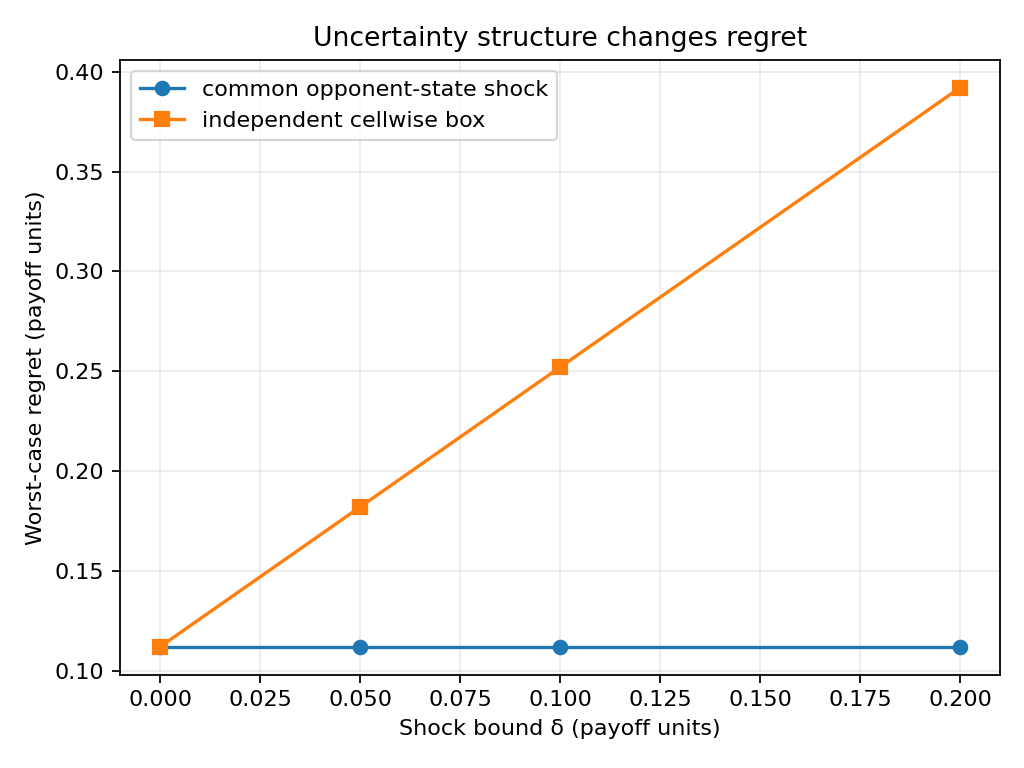

In [3]:
from IPython.display import Image, display
display(Image(filename='results/structured_uncertainty/comparison.png'))

## Figura y lectura
La figura `results/structured_uncertainty/comparison.png` muestra que la cota compartida permanece constante y la caja independiente crece. El resultado depende enteramente del conjunto de incertidumbre supuesto. No identifica el proceso generador de shocks ni demuestra un equilibrio nuevo.